# Stage Three: Exploratory Data Analysis

What changed at the top of the market between the 2023 and 2026 editions of the same sales?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")
THEN, NOW = "#7FA3BF", "#B8945A"
ERA_ORDER = ["Pre-war", "1946-69", "1970s", "1980s-90s", "2000s on"]
ERA_COLOURS = ["#6E6259", "#9DB3C4", "#CFC6B6", "#D9B57A", "#8A6A32"]

In [2]:
lots = pd.read_csv("../data/processed/top_lots_clean.csv")
lots["era"] = pd.Categorical(lots["era"], categories=ERA_ORDER, ordered=True)
totals = pd.read_csv("../data/processed/sale_totals_clean.csv", index_col="week")

## Stage Three - Part One: Sale totals, three years apart

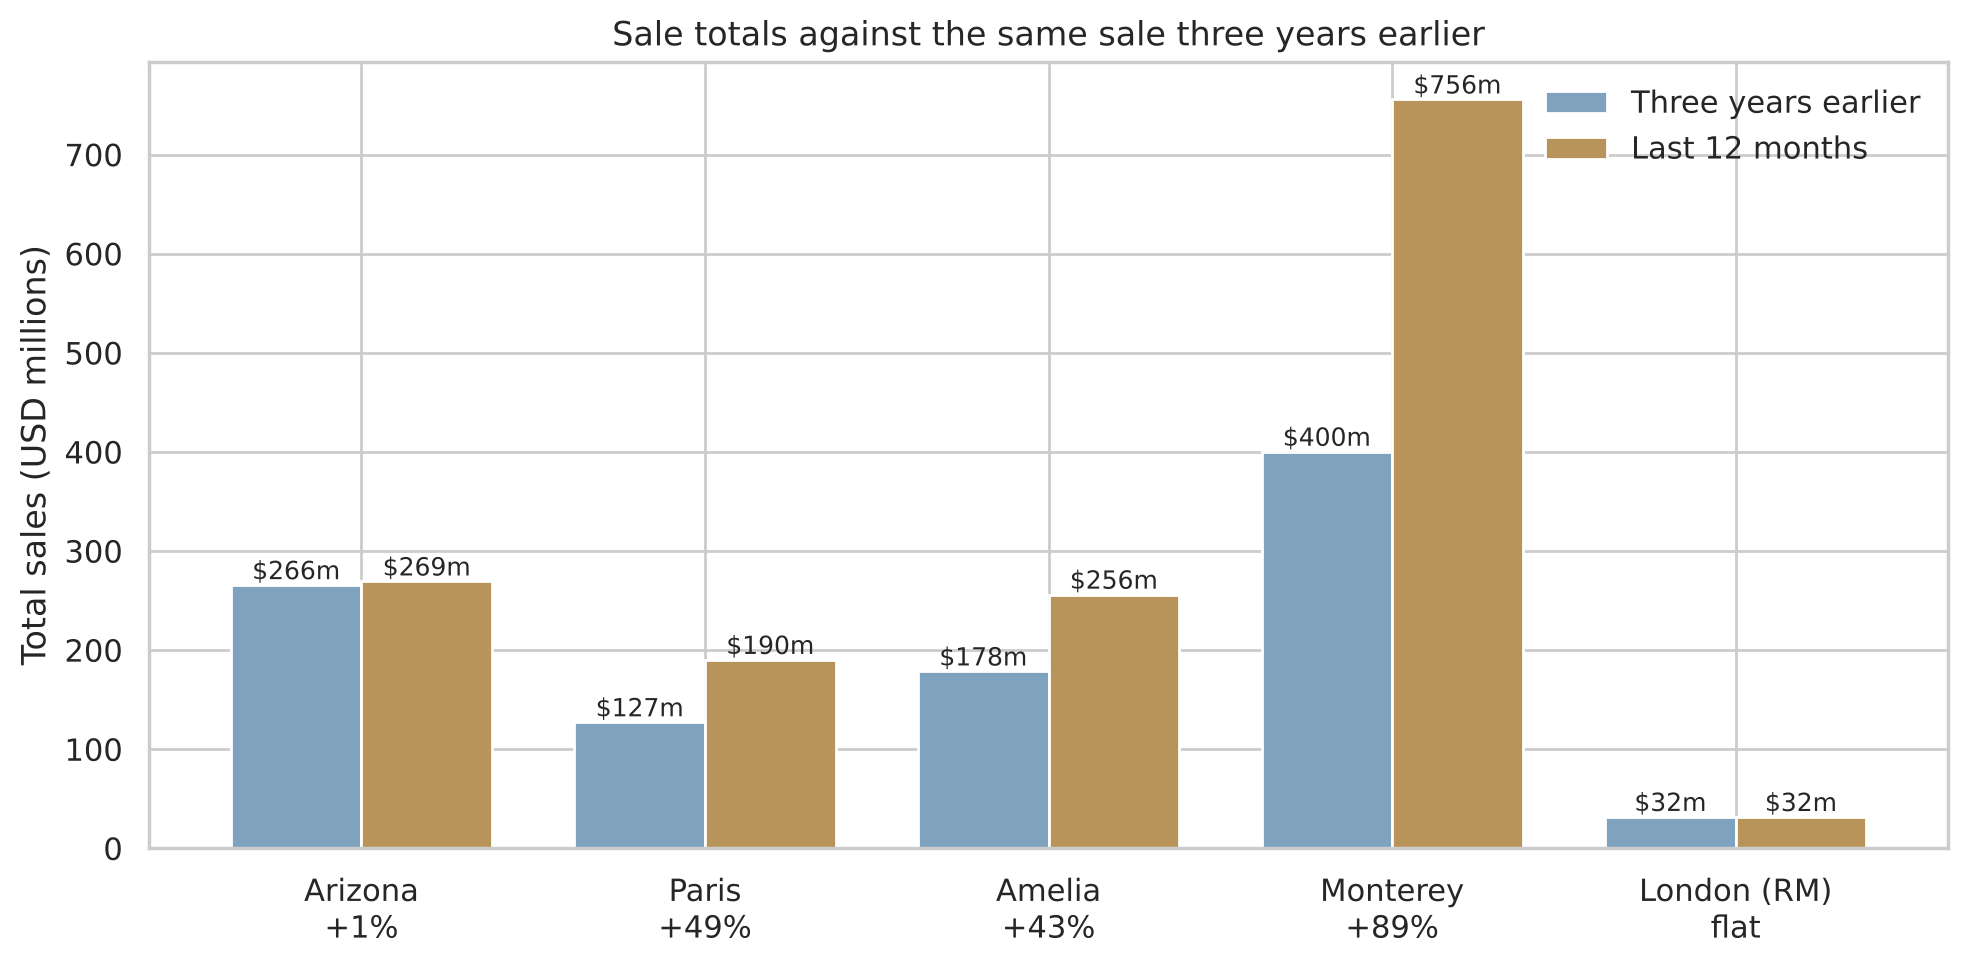

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(totals))
w = 0.38
b1 = ax.bar(x - w/2, totals["Then"], w, color=THEN, label="Three years earlier")
b2 = ax.bar(x + w/2, totals["Now"], w, color=NOW, label="Last 12 months")
ax.bar_label(b1, fmt="$%.0fm", fontsize=9)
ax.bar_label(b2, fmt="$%.0fm", fontsize=9)
labels = [f"{w}\n" + ("flat" if abs(c) < 0.5 else f"{c:+.0f}%") for w, c in zip(totals.index, totals["change_pct"])]
ax.set_xticks(x, labels)
ax.set_ylabel("Total sales (USD millions)")
ax.set_title("Sale totals against the same sale three years earlier")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("../images/sale_totals.png", dpi=150, bbox_inches="tight")
plt.show()

Monterey nearly doubled, and Paris and Amelia rose by around half. Arizona, dominated by Barrett-Jackson's no-reserve sale, was flat, as was RM Sotheby's London in dollars. The growth is concentrated in the high-end sales.

## Stage Three - Part Two: Where the money went, by era

In [4]:
era_value = (lots.groupby(["when", "era"], observed=False)["price_usd"].sum()
             .unstack().loc[["Then", "Now"]])
era_share = era_value.div(era_value.sum(axis=1), axis=0) * 100
era_share.round(1)

era,Pre-war,1946-69,1970s,1980s-90s,2000s on
when,,,,,
Then,12.7,55.4,5.0,13.5,13.5
Now,6.0,29.7,2.2,25.9,36.2


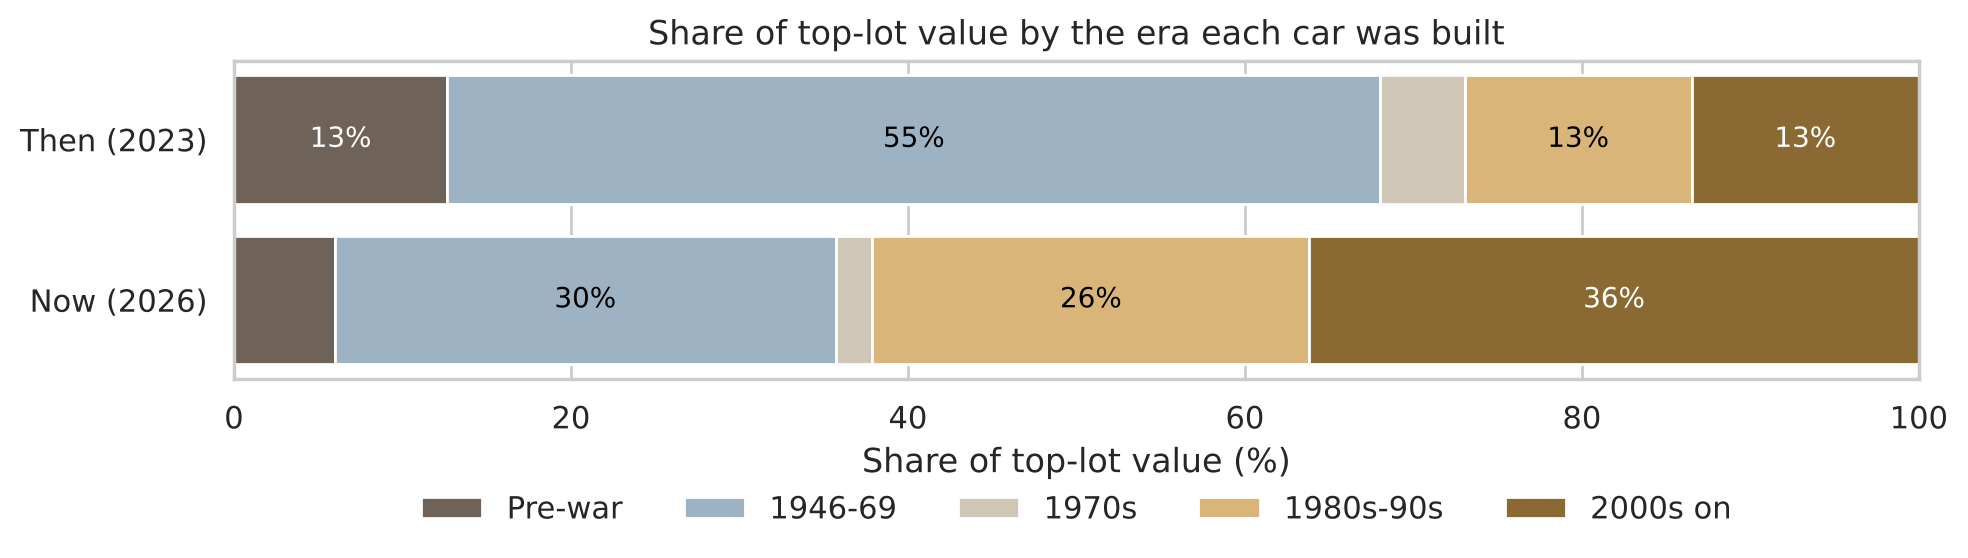

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.2))
left = np.zeros(2)
for era_name, colour in zip(ERA_ORDER, ERA_COLOURS):
    vals = era_share[era_name].values
    ax.barh(["Then (2023)", "Now (2026)"], vals, left=left, color=colour, label=era_name)
    for i, v in enumerate(vals):
        if v >= 7:
            ax.text(left[i] + v/2, i, f"{v:.0f}%", ha="center", va="center",
                    color="white" if era_name in ("Pre-war", "2000s on") else "black", fontsize=10)
    left += vals
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_xlabel("Share of top-lot value (%)")
ax.set_title("Share of top-lot value by the era each car was built")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.28), frameon=False)
plt.tight_layout()
plt.savefig("../images/era_share.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
by_sale = (lots.assign(v=lots["price_usd"] * lots["built_1980_on"])
           .groupby(["week", "when"])
           .apply(lambda g: g["v"].sum() / g["price_usd"].sum() * 100, include_groups=False)
           .unstack()[["Then", "Now"]])
by_sale.columns.name = "% of value from cars built 1980 on"
by_sale.round(1)

% of value from cars built 1980 on,Then,Now
week,,
Amelia,33.6,62.1
Arizona (RM Sotheby's),39.0,93.2
Monterey,12.2,58.0
Paris (RM Sotheby's),67.3,63.1


Across the four sales, cars built since 1980 went from about a quarter of the money at the top to nearly two-thirds. Paris is the exception: its 2023 sale was already led by a new $10.7m Bugatti Chiron Profilée.

## Stage Three - Part Three: How old is a top lot?

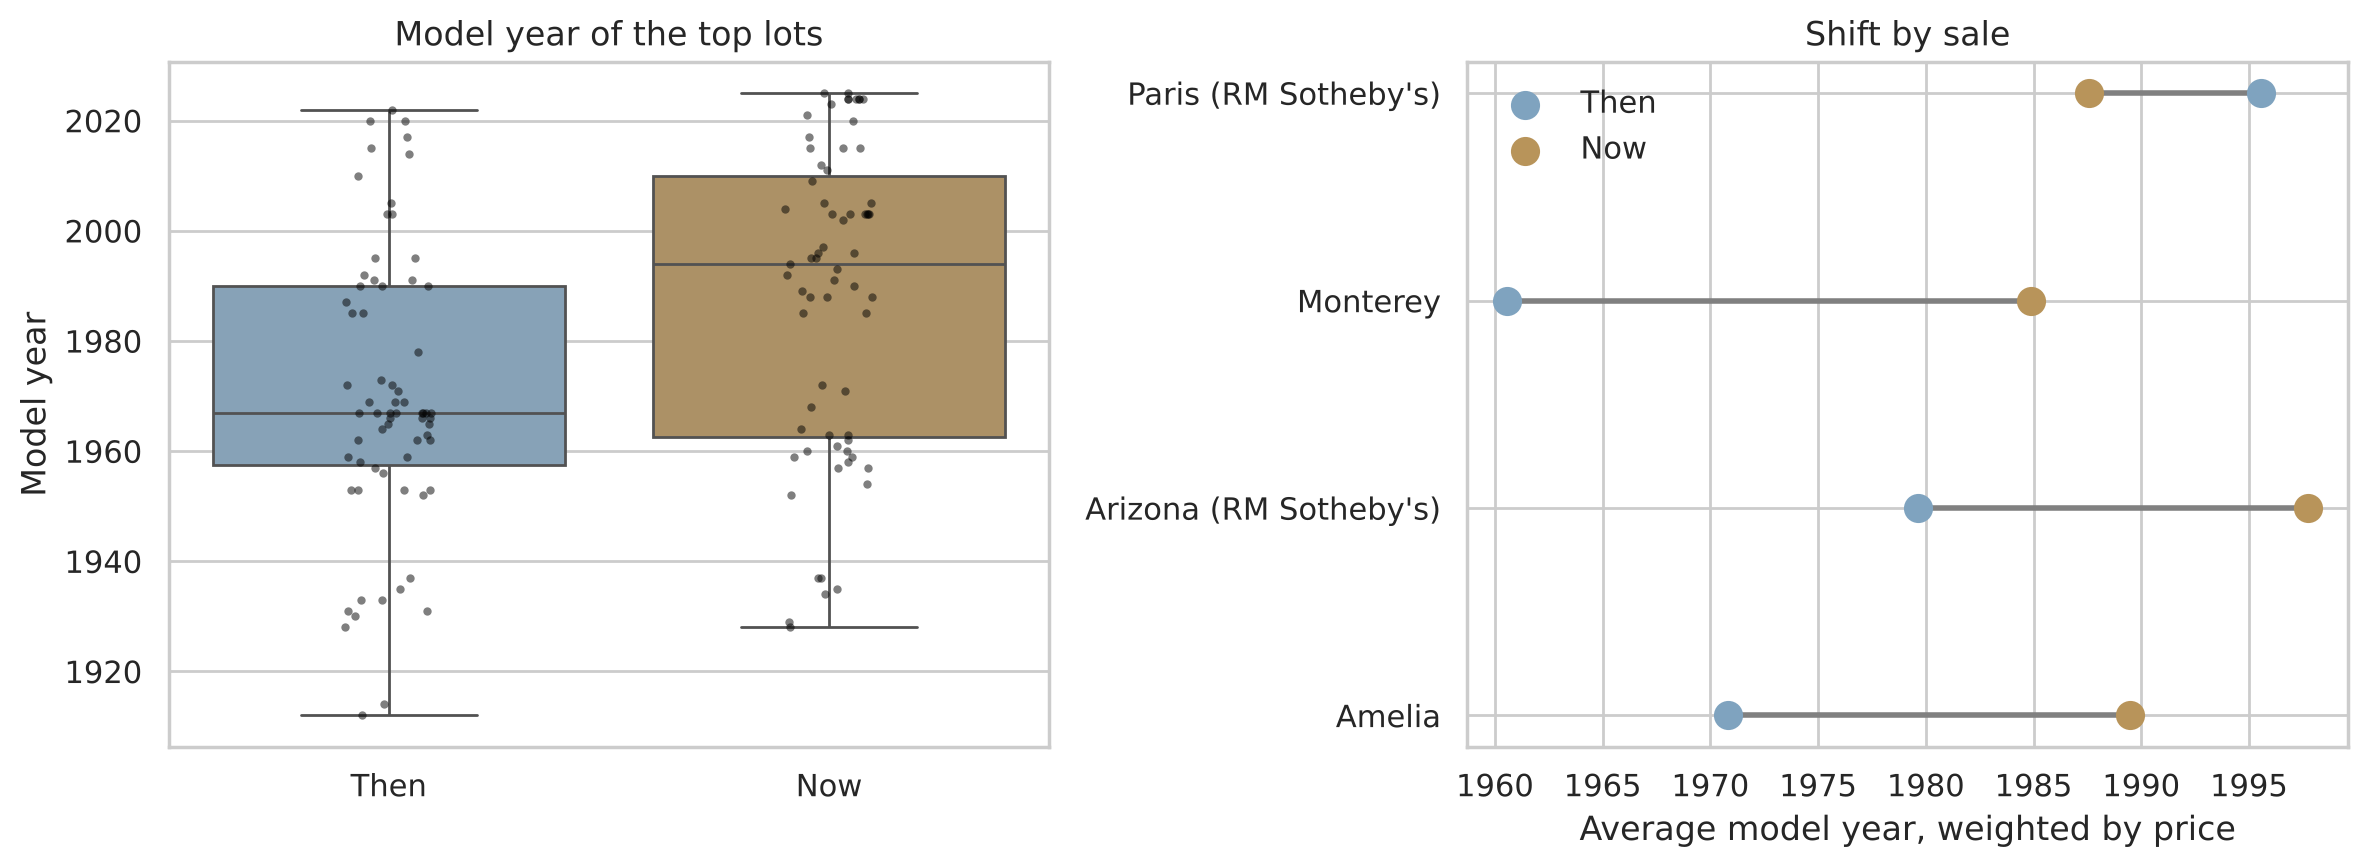

when
Now     1994.0
Then    1967.0
Name: year, dtype: float64

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=lots, x="when", y="year", order=["Then", "Now"], hue="when",
            palette={"Then": THEN, "Now": NOW}, legend=False, ax=axes[0])
sns.stripplot(data=lots, x="when", y="year", order=["Then", "Now"], color="black",
              size=3, alpha=0.5, ax=axes[0])
axes[0].set_xlabel("")
axes[0].set_ylabel("Model year")
axes[0].set_title("Model year of the top lots")

summary = lots.groupby(["week", "when"]).apply(
    lambda g: np.average(g["year"], weights=g["price_usd"]), include_groups=False).unstack()[["Then", "Now"]]
for i, (sale, row) in enumerate(summary.iterrows()):
    axes[1].plot([row["Then"], row["Now"]], [i, i], color="grey", lw=2, zorder=1)
    axes[1].scatter(row["Then"], i, color=THEN, s=90, zorder=2, label="Then" if i == 0 else None)
    axes[1].scatter(row["Now"], i, color=NOW, s=90, zorder=2, label="Now" if i == 0 else None)
axes[1].set_yticks(range(len(summary)), summary.index)
axes[1].set_xlabel("Average model year, weighted by price")
axes[1].set_title("Shift by sale")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.savefig("../images/model_year_shift.png", dpi=150, bbox_inches="tight")
plt.show()

lots.groupby("when")["year"].median()

## Stage Three - Part Four: Every lot, by model year and price

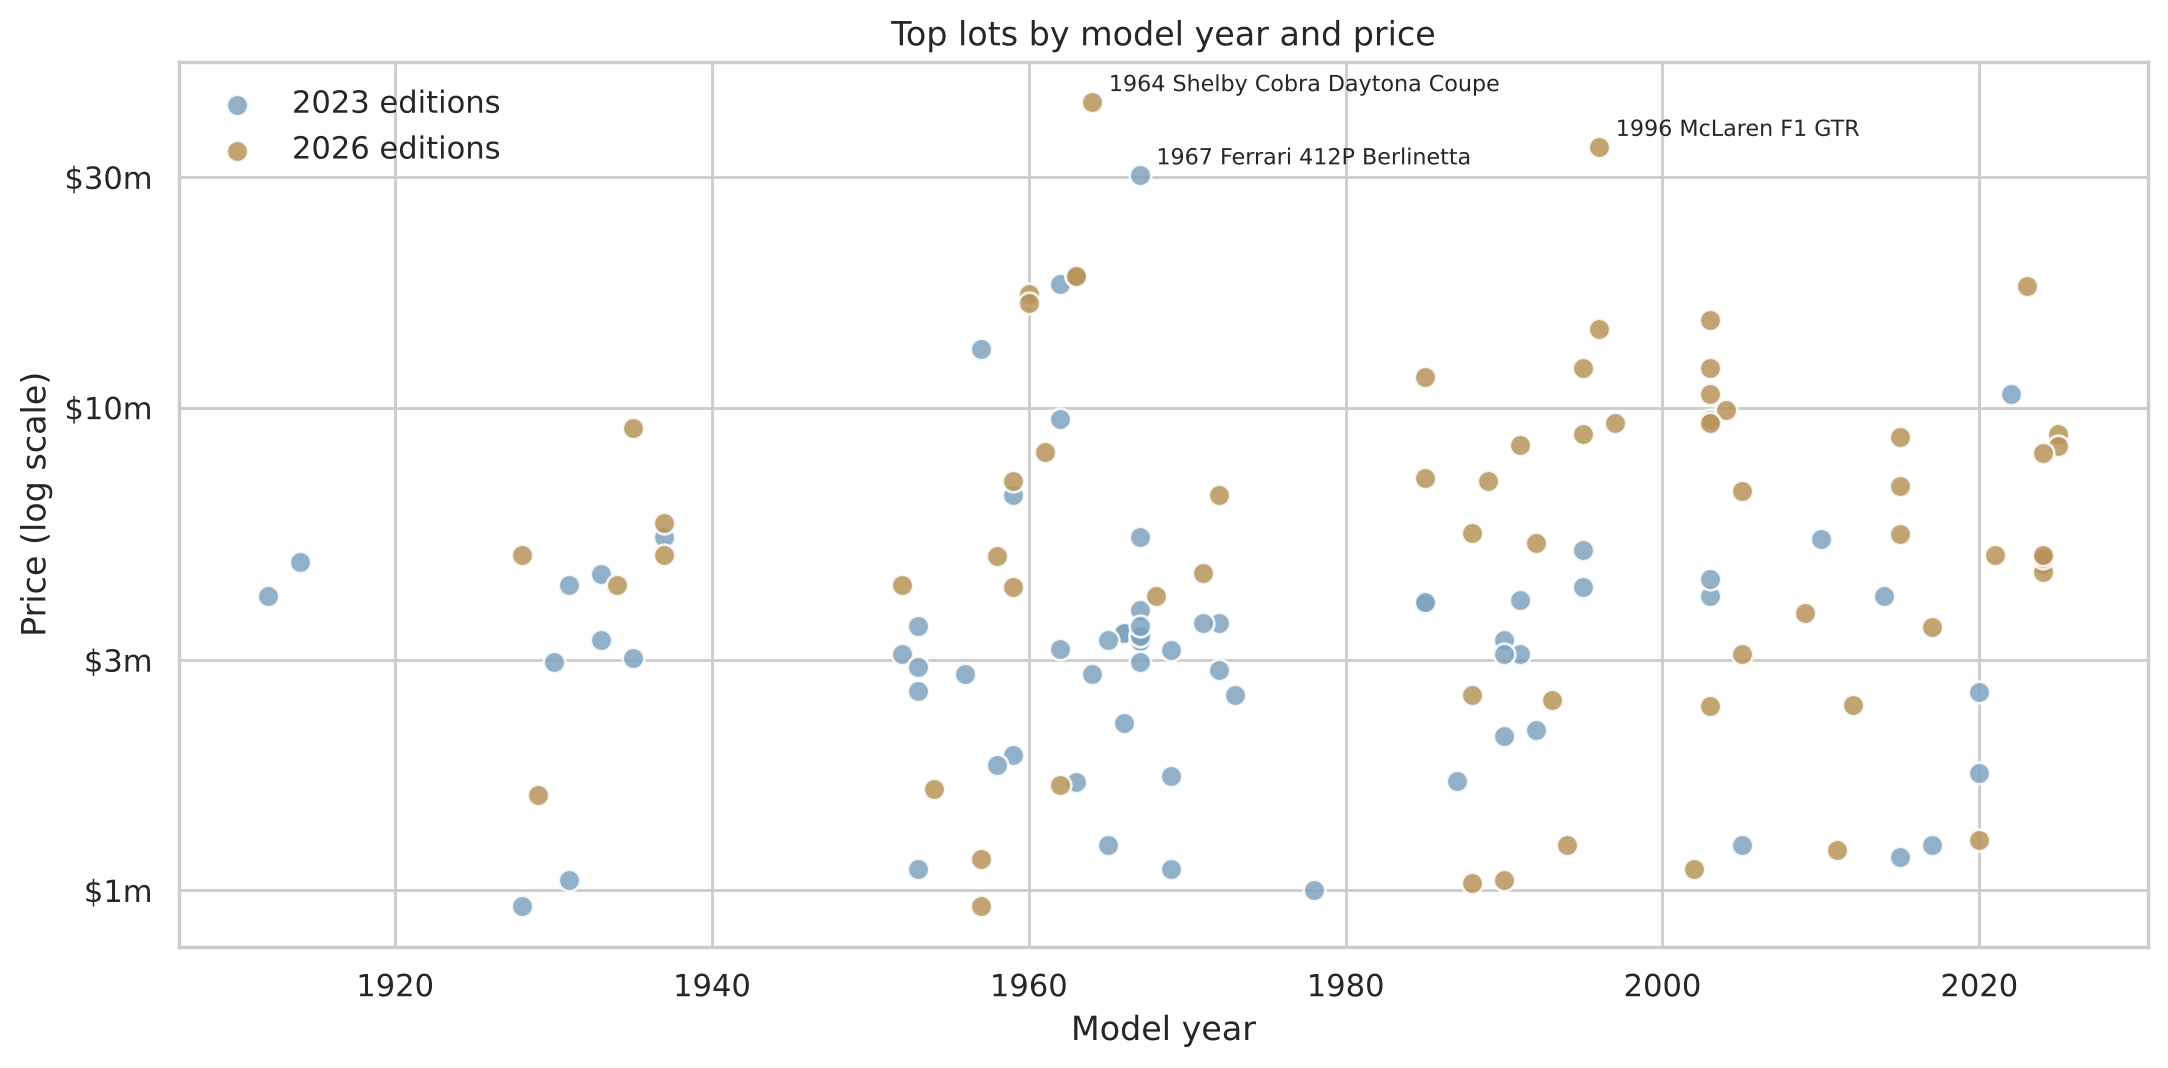

In [8]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for when, colour, label in [("Then", THEN, "2023 editions"), ("Now", NOW, "2026 editions")]:
    d = lots[lots["when"] == when]
    ax.scatter(d["year"], d["price_m"], s=60, color=colour, alpha=0.85, edgecolor="white", label=label)
ax.set_yscale("log")
ax.set_yticks([1, 3, 10, 30], ["$1m", "$3m", "$10m", "$30m"])
ax.set_xlabel("Model year")
ax.set_ylabel("Price (log scale)")
ax.set_title("Top lots by model year and price")
for _, r in lots.nlargest(3, "price_usd").iterrows():
    ax.annotate(f"{r['year']} {r['car']}", (r["year"], r["price_m"]), xytext=(6, 4),
                textcoords="offset points", fontsize=8)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("../images/year_vs_price.png", dpi=150, bbox_inches="tight")
plt.show()

## Stage Three - Part Five: The top tens, side by side

In [9]:
top = (lots.sort_values("price_usd", ascending=False)
        .groupby("when").head(10)
        .assign(price=lambda d: d["price_m"].map("${:.1f}m".format))
        [["when", "year", "car", "week", "price"]])
then_top = top[top["when"] == "Then"].drop(columns="when").reset_index(drop=True)
now_top = top[top["when"] == "Now"].drop(columns="when").reset_index(drop=True)
pd.concat({"2023 editions": then_top, "2026 editions": now_top}, axis=1)

2023 editions                                                                     2026 editions                                        \
           year                                   car                  week   price          year                                   car   
0          1967               Ferrari 412P Berlinetta              Monterey  $30.3m          1964            Shelby Cobra Daytona Coupe   
1          1962  Ferrari 250 GT SWB California Spider                Amelia  $18.0m          1996                        McLaren F1 GTR   
2          1957                           Jaguar XKSS              Monterey  $13.2m          1963        Chevrolet Corvette Grand Sport   
3          2022               Bugatti Chiron Profilee  Paris (RM Sotheby's)  $10.7m          1963                         Ferrari 250 P   
4          1962         Ferrari 250 GT SWB Berlinetta              Monterey   $9.5m          2023                   Ferrari Daytona SP3   
5          1959   Ferrari 410 Superamerica Series III              Monterey   $6.6m          1960  Ferrari 250 GT SWB California Spider   
6          1967           Ferrari 275 GTB/4 (McQueen)              Monterey   $5.4m          1960  Ferrari 250 GT SWB California Spider   
7          1937   Bugatti Type 57SC Tourer by Corsica              Monterey   $5.4m          2003                          Ferrari Enzo   
8          2010                        Pagani Zonda R                Amelia   $5.3m          1996                           Ferrari F50   
9          1995                           Ferrari F50                Amelia   $5.1m          1995                           Ferrari F50   

                                 
                   week   price  
0              Monterey  $42.9m  
1              Monterey  $34.7m  
2              Monterey  $18.7m  
3              Monterey  $18.7m  
4              Monterey  $17.8m  
5  Paris (RM Sotheby's)  $17.2m  
6                Amelia  $16.5m  
7                Amelia  $15.2m  
8              Monterey  $14.6m  
9              Monterey  $12.1m